# R3a v2 — YOLO + ByteTrack + reglas, ajustadas en **validación**

**Qué pasó en v1** (queda en el reporte como primer intento):
- AUC de las reglas en test **0.563** (casi azar); alertas 5/30 en positivas, 2/30 en negativas.
- Diagnóstico (sin mirar etiquetas): muchos scores pegados en **0.50** = regla de *giro* saturada por el **temblor de cajas chicas** (la velocidad se medía en diagonales de caja, y una caja de 10 px que tiembla 2 px "va rápido"); 9 ventanas sin tracks útiles (autos lejanos/noche).
- Además v1 tenía mal el formato de la ROI (`xywh` en vez de `cx, cy, w, h`) y muestreaba 7.5 o 15 fps en videos de 15 fps.

**Qué cambia en v2:**

| | v1 | v2 | Por qué (sin usar etiquetas) |
|---|---|---|---|
| Resolución YOLO | 640 | **960** (nativa del video) | autos de 5–15 px se pierden al reducir |
| Confianza | 0.25 | **0.10** | ByteTrack usa detecciones de baja confianza en su segunda asociación; con 0.25 se le quitaban |
| Muestreo | paso entero | **10 fps por tiempo** | |
| Velocidad | ÷ diagonal | ÷ max(diagonal, 4 % de la imagen) | el temblor de cajas chicas ya no es velocidad |
| Giro | frame a frame, saturado | dirección media 0.5 s antes vs después, graduado | |
| Contacto | cualquier traslape | solo si alguno venía en movimiento | filas y estacionados no cuentan |
| Umbrales | fijos | **búsqueda en validación**, test una sola vez | |

*Analogía:* ajustar las reglas mirando el test es como estudiar con las respuestas del examen: saldría alto, pero no diría nada. Aquí se estudia con la **validación** (videos del split train que R2c apartó) y el examen (test) se presenta una vez.

Las ventanas de validación y test se reconstruyen con el **código literal de R2c**, y se comprueba que el test sale idéntico a las 60 ventanas de R2c.

In [ ]:
# ===== 1. Configuración =====
HUELLA = "ebfa594f"
VERSION = "v2"
YOLO_PESOS = "yolov8n.pt"
FPS_TRACK = 10
IMGSZ = 960          # resolución nativa de ACCIDENT (960×720)
CONF = 0.10          # ByteTrack necesita las detecciones de baja confianza
IMGSZ_BENCH = [640, 960]

# Búsqueda en validación (81 combinaciones). Los parámetros de cinemática (MIN_PUNTOS, CONF_MIN, SUAVIZADO,
# DIAG_MIN) quedan fijos para no recalcular trayectorias.
REJILLA = dict(V_MIN=[0.4, 0.6, 0.9], IOU_CONTACTO=[0.01, 0.03, 0.08], GIRO_MIN=[40, 60, 90], PESO_SOLO=[0.3, 0.5, 0.8])

In [ ]:
# ===== 2. Instalación, Drive, GPU =====
!pip -q install ultralytics lap "kaggle>=1.7"
import os, re, json, time, glob, zipfile, random, shutil, subprocess, itertools, sys
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, torch, cv2
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')
GPU = torch.cuda.is_available()
print('GPU:', torch.cuda.get_device_name(0) if GPU else 'NINGUNA (Entorno → Cambiar tipo → T4)')

# Mismas rutas y semilla que R2c
DIR_PERSISTENTE = "/content/drive/MyDrive/roadvision"
DIR_LOCAL = "/content/datos_roadvision"
DIR_ACC = os.path.join(DIR_LOCAL, "accident")
DIR_RESULTADOS = os.path.join(DIR_PERSISTENTE, "resultados_qwen")
SALIDA = os.path.join(DIR_RESULTADOS, f"r3_{HUELLA}")
for d in (DIR_ACC, SALIDA):
    os.makedirs(d, exist_ok=True)
SEMILLA = 0
rng = random.Random(SEMILLA)
print('salida:', SALIDA)

Mounted at /content/drive
GPU: Tesla T4
salida: /content/drive/MyDrive/roadvision/resultados_qwen/r3_ebfa594f


## 3. Ventanas de R2c (código literal): metadatos de ACCIDENT y generación de ventanas

In [ ]:
# --- R2c, sección 1 ---
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
DATASET = "picekl/accident"


def kaggle(*args, timeout=300):
    try:
        r = subprocess.run(["kaggle", *args], capture_output=True, text=True, timeout=timeout,
                           stdin=subprocess.DEVNULL)
    except subprocess.TimeoutExpired:
        raise RuntimeError(f"kaggle {' '.join(args[:3])} tardó más de {timeout} s")
    if r.returncode != 0:
        raise RuntimeError(r.stderr or r.stdout)
    return r.stdout


def bajar(nombre):
    """Baja un archivo del dataset a DIR_ACC/nombre (si no está). Devuelve (nombre, ok)."""
    destino = os.path.join(DIR_ACC, nombre)
    if os.path.exists(destino):
        return nombre, True
    os.makedirs(os.path.dirname(destino), exist_ok=True)
    for intento in range(3):
        try:
            kaggle("datasets", "download", DATASET, "-f", nombre, "-p", os.path.dirname(destino))
            z = destino + ".zip"
            if os.path.exists(z):
                with zipfile.ZipFile(z) as zz:
                    zz.extractall(os.path.dirname(destino))
                os.remove(z)
            return nombre, os.path.exists(destino)
        except RuntimeError:
            time.sleep(2 * (intento + 1))
    return nombre, False


def bajar_varios(nombres, hilos=8):
    nombres = list(dict.fromkeys(nombres))
    t0, hechos, fallos = time.time(), 0, []
    with ThreadPoolExecutor(hilos) as ex:
        for nombre, ok in ex.map(bajar, nombres):
            hechos += 1
            if not ok:
                fallos.append(nombre)
            if hechos % 25 == 0 or hechos == len(nombres):
                print(f"  {hechos}/{len(nombres)} · {time.time()-t0:.0f} s", flush=True)
    if fallos:
        print(f"⚠️  {len(fallos)} no se pudieron bajar (se ignoran):", fallos[:5])
    return [n for n in nombres if n not in fallos]


print("Probando sesión de Kaggle...", end=" ", flush=True)
kaggle("datasets", "list", "-s", "accident", timeout=60)
print("OK")
for t in ("metadata-real.csv", "metadata-synthetic.csv"):
    bajar(t)
real = pd.read_csv(os.path.join(DIR_ACC, "metadata-real.csv"))
sint = pd.read_csv(os.path.join(DIR_ACC, "metadata-synthetic.csv"))
print("real:", real.shape, real["split_in_distribution"].value_counts().to_dict())
print("sintético:", sint.shape)

Probando sesión de Kaggle... OK
real: (2027, 22) {'test': 1520, 'train': 507}
sintético: (2211, 19)


In [ ]:
# --- R2c, sección 2 ---
VENTANA_S, MARGEN_S, MIN_NEG_S = 8.0, 3.0, 4.0
T_MIN_NEG = MARGEN_S + MIN_NEG_S
N_SINTETICOS = 300
FRAC_VAL = 0.10
MAX_EJEMPLOS = 800
MIN_NEG_TEST = 30


def roi_de(f):
    """Caja del choque normalizada (cx, cy, ancho, alto); None si faltan datos."""
    try:
        x1, y1, x2, y2 = (float(f[k]) for k in ("x1", "y1", "x2", "y2"))
        cx, cy = float(f["center_x"]), float(f["center_y"])
    except (KeyError, TypeError, ValueError):
        return None
    if any(np.isnan([x1, y1, x2, y2, cx, cy])):
        return None
    return (cx, cy, max(x2 - x1, 0.01), max(y2 - y1, 0.01))


def ventanas_de(video_id, ruta_rel, t, dur, tipo, contexto, dominio, r, n_neg=1, roi=None):
    out = []
    antes = r.uniform(1.5, VENTANA_S - 1.5)
    ini = max(0.0, min(t - antes, dur - VENTANA_S))
    out.append({"clase": "positiva", "inicio": ini, "fin": min(dur, ini + VENTANA_S), "t_rel": t - ini})
    fin_max = t - MARGEN_S
    for _ in range(n_neg):
        if fin_max < MIN_NEG_S:
            break
        largo = min(VENTANA_S, fin_max)
        fin = r.uniform(max(largo, fin_max - 4.0), fin_max)
        out.append({"clase": "negativa", "inicio": max(0.0, fin - largo), "fin": fin, "t_rel": None})
    for v in out:
        v.update({"video": video_id, "ruta_rel": ruta_rel, "t_choque": t, "tipo_real": tipo,
                  "contexto": contexto, "dominio": dominio, "roi": roi})
    return out


def contexto_real(f):
    return {"lugar": f.get("scene_layout"), "hora": f.get("day_time"), "clima": f.get("weather")}


def contexto_sint(f):
    return {"lugar": None, "hora": "night" if "night" in str(f.get("weather")) else "day", "clima": f.get("weather")}


tr = real[real["split_in_distribution"] == "train"].copy()
tr["video"] = tr["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
videos_tr = sorted(tr["video"].unique())
rng.shuffle(videos_tr)
n_val = max(5, int(len(videos_tr) * FRAC_VAL))
VIDEOS_VAL = set(videos_tr[:n_val])
tr["grupo"] = np.where(tr["video"].isin(VIDEOS_VAL), "val", "train")

por_tipo = N_SINTETICOS // sint["type"].nunique()
si = sint.sample(frac=1, random_state=SEMILLA).groupby("type").head(por_tipo).copy()
si["video"] = si["rgb_path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])

candidatas = []
for _, f in tr.iterrows():
    for v in ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                         contexto_real(f), "real", rng, n_neg=2, roi=roi_de(f)):
        v["grupo"] = f["grupo"]; candidatas.append(v)
for _, f in si.iterrows():
    for v in ventanas_de(f["video"], f["rgb_path"], f["accident_time"], f["duration"], f["type"],
                         contexto_sint(f), "sintetico", rng, n_neg=2, roi=roi_de(f)):
        v["grupo"] = "train"; candidatas.append(v)
CAND = pd.DataFrame(candidatas)
print(CAND.groupby(["grupo", "dominio", "clase"]).size().unstack(fill_value=0))
print("Ventanas sin caja del choque (se usa el frame completo):", int(CAND["roi"].isna().sum()))

mitad = MAX_EJEMPLOS // 2
tr_c = CAND[CAND["grupo"] == "train"]
neg = tr_c[tr_c["clase"] == "negativa"]
neg = neg.sample(mitad, replace=len(neg) < mitad, random_state=SEMILLA)
pos = tr_c[tr_c["clase"] == "positiva"]
pos = pos.sample(frac=1, random_state=SEMILLA).groupby("dominio").head(mitad // 2)
pos = pd.concat([pos, tr_c[(tr_c["clase"] == "positiva") & ~tr_c.index.isin(pos.index)].sample(
    max(0, mitad - len(pos)), random_state=SEMILLA)])
TRAIN = pd.concat([pos, neg]).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)
VAL = CAND[CAND["grupo"] == "val"].reset_index(drop=True)

# Test: mismo procedimiento y semilla que R2b (sin CSV de R2a)
te = real[real["split_in_distribution"] == "test"].copy()
te["video"] = te["path"].map(lambda p: os.path.splitext(os.path.basename(p))[0])
extra = te[te["accident_time"] >= T_MIN_NEG].sample(frac=1, random_state=SEMILLA)
r_test, filas_test = random.Random(SEMILLA + 1), []
for _, f in extra.iterrows():
    if sum(x["clase"] == "negativa" for x in filas_test) >= MIN_NEG_TEST:
        break
    filas_test += ventanas_de(f["video"], f["path"], f["accident_time"], f["duration"], f["type"],
                              contexto_real(f), "real", r_test, n_neg=1, roi=roi_de(f))
TEST = pd.DataFrame(filas_test)
assert not (set(TEST["video"]) & (set(TRAIN["video"]) | set(VAL["video"]))), "¡Fuga test↔train!"
for nombre, df in (("TRAIN", TRAIN), ("VAL", VAL), ("TEST", TEST)):
    print(f"{nombre}: {len(df)} ventanas · {df['clase'].value_counts().to_dict()}")

clase            negativa  positiva
grupo dominio                      
train real            186       457
      sintetico       270       300
val   real             14        50
Ventanas sin caja del choque (se usa el frame completo): 0
TRAIN: 800 ventanas · {'positiva': 400, 'negativa': 400}
VAL: 64 ventanas · {'positiva': 50, 'negativa': 14}
TEST: 60 ventanas · {'positiva': 30, 'negativa': 30}


In [ ]:
# ===== Comprobación: el TEST reconstruido es exactamente el de R2c =====
csv_test = pd.read_csv(os.path.join(DIR_RESULTADOS, f"test_roi_lora_{HUELLA}.csv"))
llave = lambda df: set(zip(df['video'], df['clase'], df['inicio'].round(3)))
assert llave(TEST) == llave(csv_test), 'El TEST reconstruido no coincide con el de R2c'
print('✔ TEST = las 60 ventanas de R2c')

def preparar(df, grupo):
    df = df.copy()
    df['grupo'] = grupo
    df['y'] = (df['clase'] == 'positiva').astype(int)
    df['key'] = df['video'] + '|' + df['clase'] + '|' + df['inicio'].round(3).astype(str)
    df['wid'] = df['video'] + '|' + df['inicio'].round(3).astype(str)   # la llave que usa R3b
    df['ruta_local'] = df['ruta_rel'].map(lambda n: os.path.join(DIR_ACC, n))
    return df

V = pd.concat([preparar(VAL, 'val'), preparar(TEST, 'test')], ignore_index=True)
V = V[V['roi'].notna()]
n_dup = int(V.duplicated('key').sum())
V = V.drop_duplicates('key').reset_index(drop=True)   # en R2c el 2.º corte negativo sale igual en videos cortos
print(f'Ventanas repetidas descartadas: {n_dup}')
print(V.groupby(['grupo', 'clase']).size().unstack())

✔ TEST = las 60 ventanas de R2c
Ventanas repetidas descartadas: 5
clase  negativa  positiva
grupo                    
test         30        30
val           9        50


In [ ]:
# ===== 4. Videos de validación y test (reusa el ZIP si ya está) =====
faltan = sorted(set(V.loc[~V.ruta_local.map(os.path.exists), 'ruta_rel']))
print('Videos que faltan:', len(faltan))
if faltan:
    zips = [z for z in glob.glob(f'{DIR_LOCAL}/*.zip') + glob.glob('/content/accident_zip/*.zip') if zipfile.is_zipfile(z)]
    if not zips:
        !kaggle datasets download picekl/accident -p {DIR_LOCAL}
        zips = glob.glob(f'{DIR_LOCAL}/*.zip')
    with zipfile.ZipFile(zips[0]) as zf:
        miembros = set(zf.namelist())
        for n in faltan:
            if n in miembros:
                zf.extract(n, DIR_ACC)
V = V[V.ruta_local.map(os.path.exists)].reset_index(drop=True)
print(V.groupby(['grupo', 'clase']).size().unstack())
assert (V.grupo == 'test').sum() == 60

Videos que faltan: 80
Dataset URL: https://www.kaggle.com/datasets/picekl/accident
License(s): CC-BY-NC-SA-4.0
100% 15.6G/15.6G [02:36<00:00, 107MB/s]

clase  negativa  positiva
grupo                    
test         30        30
val           9        50


In [ ]:
# ===== 5. Paso 1 y reglas v1/v2 como módulos =====
open('pipeline_v2.py', 'w').write('# ===== Paso 1: lectura de ventana + YOLO + ByteTrack =====\nimport cv2, time, numpy as np, pandas as pd\n\nCLASES = {0: \'persona\', 1: \'bici\', 2: \'auto\', 3: \'moto\', 5: \'autobus\', 7: \'camion\'}\n\n\ndef leer_ventana(ruta, inicio, fin, fps_obj):\n    """Lectura secuencial; se queda con un frame cada 1/fps_obj segundos (por tiempo, no por índice).\n    v1 usaba un paso entero y en videos de 15 fps salían 7.5 o 15 fps en vez de 10."""\n    cap = cv2.VideoCapture(ruta)\n    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0\n    i0, i1 = int(round(inicio * fps)), int(round(fin * fps))\n    cap.set(cv2.CAP_PROP_POS_FRAMES, i0)\n    frames, ts, i, sig = [], [], i0, inicio\n    while i < i1:\n        ok, f = cap.read()\n        if not ok:\n            break\n        t = i / fps\n        if t + 1e-6 >= sig:\n            frames.append(f); ts.append(t)\n            sig += 1.0 / fps_obj\n            while sig <= t:\n                sig += 1.0 / fps_obj\n        i += 1\n    cap.release()\n    return frames, np.array(ts), fps\n\n\ndef reiniciar_tracker(modelo):\n    p = getattr(modelo, \'predictor\', None)\n    if p is not None and hasattr(p, \'trackers\'):\n        for tr in p.trackers:\n            tr.reset()\n\n\ndef precision_kw(gpu):\n    """fp16 en GPU. Ultralytics ≥ 8.4 cambió `half=True` por `quantize=16`."""\n    from ultralytics.cfg import DEFAULT_CFG_DICT\n    if not gpu:\n        return {}\n    return {\'quantize\': 16} if \'quantize\' in DEFAULT_CFG_DICT else {\'half\': True}\n\n\ndef trackear(modelo, frames, ts, imgsz=640, conf=0.25, prec=None, tracker=\'bytetrack.yaml\'):\n    reiniciar_tracker(modelo)\n    filas, tiempos = [], []\n    for f, t in zip(frames, ts):\n        t0 = time.perf_counter()\n        r = modelo.track(f, persist=True, tracker=tracker, classes=list(CLASES), conf=conf,\n                         imgsz=imgsz, verbose=False, **(prec or {}))[0]\n        tiempos.append(time.perf_counter() - t0)\n        b = r.boxes\n        if b is None or b.id is None:\n            continue\n        for (x1, y1, x2, y2), tid, c, p in zip(b.xyxyn.cpu().numpy(), b.id.int().cpu().numpy(),\n                                               b.cls.int().cpu().numpy(), b.conf.cpu().numpy()):\n            filas.append((t, int(tid), int(c), float(p), x1, y1, x2, y2))\n    tr = pd.DataFrame(filas, columns=[\'t\', \'tid\', \'cls\', \'conf\', \'x1\', \'y1\', \'x2\', \'y2\'])\n    return tr, np.array(tiempos)\n')
open('reglas_v1.py', 'w').write('# ===== Paso 2: reglas sobre los tracks → alerta + ROI =====\n# Entrada: DataFrame de tracks de UNA ventana con columnas\n#   t (s), tid, cls, conf, x1, y1, x2, y2   (coordenadas normalizadas 0–1)\n# Salida: dict con score, alerta, caja ROI (x1,y1,x2,y2 normalizada), t_evento, motivo\nimport numpy as np\nimport pandas as pd\n\nREGLAS = dict(\n    MIN_PUNTOS=4,        # un track necesita ≥ 4 detecciones para tener velocidad\n    SUAVIZADO=3,         # mediana móvil de 3 frames sobre el centro\n    V_MIN=0.6,           # velocidad mínima "en movimiento" (diagonales de la caja por segundo)\n    VENTANA_FRENO=1.0,   # s: un choque detiene en < 1 s; frenar en semáforo tarda 2–3 s\n    CAIDA_FRENO=0.6,     # frenado brusco: la velocidad cae ≥ 60 %…\n    DECEL_MIN=0.9,       # …y además baja ≥ 0.9 diagonales/s dentro de VENTANA_FRENO (frenar suave no cuenta)\n    GIRO_MIN=50,         # grados: cambio brusco de dirección\n    IOU_CONTACTO=0.03,   # traslape mínimo entre dos cajas para "contacto"\n    ACERC_MIN=0.8,       # acercamiento: la distancia (en diagonales) baja a este ritmo por s\n    PESO_SOLO=0.5,       # un vehículo solo (frenado/giro sin contacto) pesa menos que un par\n    UMBRAL_ALERTA=0.45,  # score ≥ esto → el paso 2 dispara alerta\n)\n\n\ndef _iou(a, b):\n    x1, y1 = np.maximum(a[..., 0], b[..., 0]), np.maximum(a[..., 1], b[..., 1])\n    x2, y2 = np.minimum(a[..., 2], b[..., 2]), np.minimum(a[..., 3], b[..., 3])\n    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)\n    ar = lambda c: (c[..., 2] - c[..., 0]) * (c[..., 3] - c[..., 1])\n    return inter / np.maximum(ar(a) + ar(b) - inter, 1e-9)\n\n\ndef cinematica(tr, R=REGLAS):\n    """Por track: centro suavizado, velocidad (en diagonales/s), dirección."""\n    out = {}\n    for tid, g in tr.sort_values(\'t\').groupby(\'tid\'):\n        if len(g) < R[\'MIN_PUNTOS\']:\n            continue\n        g = g.copy()\n        g[\'cx\'] = ((g.x1 + g.x2) / 2).rolling(R[\'SUAVIZADO\'], center=True, min_periods=1).median()\n        g[\'cy\'] = ((g.y1 + g.y2) / 2).rolling(R[\'SUAVIZADO\'], center=True, min_periods=1).median()\n        g[\'diag\'] = np.hypot(g.x2 - g.x1, g.y2 - g.y1).rolling(5, center=True, min_periods=1).median()\n        dt = g.t.diff().replace(0, np.nan)\n        vx, vy = g.cx.diff() / dt, g.cy.diff() / dt\n        g[\'v\'] = (np.hypot(vx, vy) / g.diag).rolling(R[\'SUAVIZADO\'], center=True, min_periods=1).mean()\n        g[\'ang\'] = np.degrees(np.arctan2(vy, vx))\n        out[tid] = g.reset_index(drop=True)\n    return out\n\n\ndef eventos_individuales(cin, R=REGLAS):\n    """Frenado brusco y giro brusco de un solo track."""\n    ev = []\n    for tid, g in cin.items():\n        t, v, ang = g.t.values, g.v.values, g.ang.values\n        for i in range(len(g)):\n            if not np.isfinite(v[i]) or v[i] < R[\'V_MIN\']:\n                continue\n            fut = (t > t[i]) & (t <= t[i] + R[\'VENTANA_FRENO\'])\n            if not fut.any():\n                continue\n            vmin = np.nanmin(v[fut])\n            caida = 1 - vmin / v[i]\n            if caida >= R[\'CAIDA_FRENO\'] and (v[i] - vmin) >= R[\'DECEL_MIN\']:\n                j = np.where(fut)[0][np.nanargmin(v[fut])]\n                ev.append(dict(tipo=\'frenado\', tids=(tid,), t=t[j], fuerza=caida, i=j))\n            a_fut = ang[fut & (v >= R[\'V_MIN\'])]   # dirección solo cuando sí se mueve (quieto = ruido)\n            if len(a_fut) and np.isfinite(ang[i]):\n                giro = np.abs((a_fut - ang[i] + 180) % 360 - 180).max()\n                if giro >= R[\'GIRO_MIN\']:\n                    ev.append(dict(tipo=\'giro\', tids=(tid,), t=t[i], fuerza=min(giro / 90, 1.0), i=i))\n    return ev\n\n\ndef eventos_pares(cin, R=REGLAS):\n    """Contacto entre dos tracks (traslape) que se venían acercando."""\n    ev = []\n    tids = list(cin)\n    for a in range(len(tids)):\n        for b in range(a + 1, len(tids)):\n            ga, gb = cin[tids[a]], cin[tids[b]]\n            m = ga.merge(gb, on=\'t\', suffixes=(\'_a\', \'_b\'))\n            if len(m) < 2:\n                continue\n            ca = m[[\'x1_a\', \'y1_a\', \'x2_a\', \'y2_a\']].values\n            cb = m[[\'x1_b\', \'y1_b\', \'x2_b\', \'y2_b\']].values\n            iou = _iou(ca, cb)\n            toca = np.where(iou >= R[\'IOU_CONTACTO\'])[0]\n            if not len(toca):\n                continue\n            k = int(toca[0])   # inicio del contacto (no el máximo: después del choque siguen pegados)\n            iou_max = float(iou[k:k + 10].max())\n            diag = (m.diag_a + m.diag_b).values / 2\n            dist = np.hypot(m.cx_a - m.cx_b, m.cy_a - m.cy_b).values / diag\n            antes = m.t.values <= m.t.values[k]\n            if antes.sum() >= 2:\n                tt, dd = m.t.values[antes], dist[antes]\n                acerc = max(0.0, -(np.polyfit(tt, dd, 1)[0]))   # cuánto bajó la distancia por s\n            else:\n                acerc = 0.0\n            # Dos autos que ya estaban pegados (fila en semáforo) no se acercan → acerc ≈ 0\n            f_acerc = min(acerc / R[\'ACERC_MIN\'], 1.0)\n            # Frenado justo después del contacto: velocidad (del más rápido) antes vs después\n            tk, tm = m.t.values[k], m.t.values\n            vmx = np.fmax(m.v_a.values, m.v_b.values)\n            pre = (tm >= tk - 1.0) & (tm <= tk)\n            post = (tm >= tk + 0.5) & (tm <= tk + 0.5 + R[\'VENTANA_FRENO\'])\n            if pre.any() and post.any() and np.nanmedian(vmx[pre]) > 0:\n                f_freno = float(np.clip(1 - np.nanmedian(vmx[post]) / np.nanmedian(vmx[pre]), 0, 1))\n            else:\n                f_freno = 0.0\n            fuerza = min(1.0, iou_max / 0.15) * (0.5 * f_acerc + 0.5 * f_freno)\n            if fuerza > 0:\n                ev.append(dict(tipo=\'contacto\', tids=(tids[a], tids[b]), t=m.t.values[k],\n                               fuerza=fuerza, iou=iou_max, acerc=f_acerc, freno=f_freno))\n    return ev\n\n\ndef caja_evento(cin, e):\n    cajas = []\n    for tid in e[\'tids\']:\n        g = cin[tid]\n        i = int(np.argmin(np.abs(g.t.values - e[\'t\'])))\n        cajas.append(g.loc[i, [\'x1\', \'y1\', \'x2\', \'y2\']].values.astype(float))\n    c = np.array(cajas)\n    return np.r_[c[:, 0].min(), c[:, 1].min(), c[:, 2].max(), c[:, 3].max()]\n\n\ndef caja_respaldo(tr):\n    """Sin eventos: zona con más movimiento de detecciones; si no hay nada, centro de la imagen."""\n    if len(tr) == 0:\n        return np.array([0.375, 0.375, 0.625, 0.625]), \'centro\'\n    cx, cy = (tr.x1 + tr.x2) / 2, (tr.y1 + tr.y2) / 2\n    H, _, _ = np.histogram2d(cy, cx, bins=6, range=[[0, 1], [0, 1]])\n    iy, ix = np.unravel_index(np.argmax(H), H.shape)\n    cel = tr[(cx // (1 / 6)).clip(0, 5).eq(ix) & (cy // (1 / 6)).clip(0, 5).eq(iy)]\n    return np.r_[cel.x1.min(), cel.y1.min(), cel.x2.max(), cel.y2.max()], \'densidad\'\n\n\ndef evaluar_ventana(tr, R=REGLAS):\n    cin = cinematica(tr, R)\n    ev = [dict(e, score=e[\'fuerza\']) for e in eventos_pares(cin, R)]\n    ev += [dict(e, score=R[\'PESO_SOLO\'] * e[\'fuerza\']) for e in eventos_individuales(cin, R)]\n    if ev:\n        e = max(ev, key=lambda x: x[\'score\'])\n        caja, fuente = caja_evento(cin, e), e[\'tipo\']\n        score, t_ev, n = e[\'score\'], e[\'t\'], len(ev)\n    else:\n        caja, fuente = caja_respaldo(tr)\n        score, t_ev, n = 0.0, np.nan, 0\n    return dict(score=float(score), alerta=bool(score >= R[\'UMBRAL_ALERTA\']), fuente=fuente,\n                t_evento=t_ev, n_eventos=n, n_tracks=len(cin),\n                x1=caja[0], y1=caja[1], x2=caja[2], y2=caja[3])\n')
open('reglas_v2.py', 'w').write('# ===== Paso 2 (v2): reglas sobre los tracks → score, alerta y ROI =====\n# Cambios respecto a v1 (diagnóstico: scores pegados en 0.50 por "giro" de cajas chicas que tiemblan):\n#   · velocidad en diagonales de caja, pero con piso DIAG_MIN → el temblor de una caja de 10 px ya no parece velocidad\n#   · tracks cortos o de baja confianza no cuentan (MIN_PUNTOS, CONF_MIN)\n#   · giro = dirección media 0.5 s antes vs 0.5 s después (no frame a frame) y fuerza graduada, no saturada\n#   · frenado con fuerza graduada por la desaceleración\n#   · contacto solo si alguno de los dos venía en movimiento (dos autos parados en fila no cuentan)\n# Entrada: tracks de UNA ventana: t (s), tid, cls, conf, x1, y1, x2, y2 (normalizadas 0–1)\nimport numpy as np\nimport pandas as pd\n\nREGLAS = dict(\n    MIN_PUNTOS=8,        # ≥ 0.8 s de track a 10 fps\n    CONF_MIN=0.2,        # confianza media mínima del track\n    SUAVIZADO=5,         # mediana móvil sobre el centro (frames)\n    DIAG_MIN=0.04,       # piso de la diagonal de la caja (fracción de la imagen) para normalizar velocidad\n    V_MIN=0.6,           # "en movimiento" (diagonales/s)\n    VENTANA_FRENO=1.0,   # s\n    CAIDA_FRENO=0.6,     # la velocidad cae ≥ 60 %…\n    DECEL_MIN=0.9,       # …y ≥ 0.9 diagonales/s en VENTANA_FRENO\n    TRAMO_GIRO=0.5,      # s antes y después para comparar dirección\n    GIRO_MIN=50,         # grados\n    IOU_CONTACTO=0.03,\n    ACERC_MIN=0.8,\n    PESO_SOLO=0.5,\n    UMBRAL_ALERTA=0.45,  # en v2 se reemplaza por el elegido en validación\n)\n\n\ndef _med(x):\n    x = np.asarray(x, float); x = x[np.isfinite(x)]\n    return float(np.median(x)) if len(x) else np.nan\n\n\ndef _iou(a, b):\n    x1, y1 = np.maximum(a[..., 0], b[..., 0]), np.maximum(a[..., 1], b[..., 1])\n    x2, y2 = np.minimum(a[..., 2], b[..., 2]), np.minimum(a[..., 3], b[..., 3])\n    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)\n    ar = lambda c: (c[..., 2] - c[..., 0]) * (c[..., 3] - c[..., 1])\n    return inter / np.maximum(ar(a) + ar(b) - inter, 1e-9)\n\n\ndef cinematica(tr, R=REGLAS):\n    out = {}\n    for tid, g in tr.sort_values(\'t\').groupby(\'tid\'):\n        if len(g) < R[\'MIN_PUNTOS\'] or g.conf.mean() < R[\'CONF_MIN\']:\n            continue\n        g = g.drop_duplicates(\'t\').copy()\n        k = R[\'SUAVIZADO\']\n        g[\'cx\'] = ((g.x1 + g.x2) / 2).rolling(k, center=True, min_periods=1).median()\n        g[\'cy\'] = ((g.y1 + g.y2) / 2).rolling(k, center=True, min_periods=1).median()\n        g[\'diag\'] = np.maximum(np.hypot(g.x2 - g.x1, g.y2 - g.y1).rolling(k, center=True, min_periods=1).median(),\n                               R[\'DIAG_MIN\'])\n        dt = g.t.diff().replace(0, np.nan)\n        vx, vy = g.cx.diff() / dt, g.cy.diff() / dt\n        g[\'vx\'], g[\'vy\'] = vx, vy\n        g[\'v\'] = (np.hypot(vx, vy) / g.diag).rolling(3, center=True, min_periods=1).mean()\n        g.loc[g.index[:2], \'v\'] = np.nan; g.loc[g.index[-2:], \'v\'] = np.nan   # bordes del track: suavizado incompleto\n        out[tid] = g.reset_index(drop=True)\n    return out\n\n\ndef _dir_media(g, msk):\n    vx, vy = g.vx.values[msk], g.vy.values[msk]\n    ok = np.isfinite(vx) & np.isfinite(vy)\n    if ok.sum() < 2:\n        return None\n    return np.degrees(np.arctan2(vy[ok].mean(), vx[ok].mean()))\n\n\ndef eventos_individuales(cin, R=REGLAS):\n    ev = []\n    for tid, g in cin.items():\n        t, v = g.t.values, g.v.values\n        for i in range(len(g)):\n            if not np.isfinite(v[i]) or v[i] < R[\'V_MIN\']:\n                continue\n            fut = (t > t[i]) & (t <= t[i] + R[\'VENTANA_FRENO\'])\n            if fut.any() and np.isfinite(v[fut]).any():\n                vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin\n                if caida >= R[\'CAIDA_FRENO\'] and dv >= R[\'DECEL_MIN\']:\n                    j = np.where(fut)[0][np.nanargmin(v[fut])]\n                    ev.append(dict(tipo=\'frenado\', tids=(tid,), t=t[j],\n                                   fuerza=float(caida * min(1.0, dv / (2 * R[\'DECEL_MIN\'])))))\n        # giro por tramos: dirección media antes vs después de cada instante, ambos en movimiento\n        T = R[\'TRAMO_GIRO\']\n        for i in range(0, len(g), 2):\n            antes = (t >= t[i] - T) & (t < t[i]); desp = (t > t[i]) & (t <= t[i] + T)\n            if antes.sum() < 3 or desp.sum() < 3:\n                continue\n            if not (_med(v[antes]) >= R[\'V_MIN\'] and _med(v[desp]) >= R[\'V_MIN\']):\n                continue\n            a, b = _dir_media(g, antes), _dir_media(g, desp)\n            if a is None or b is None:\n                continue\n            giro = abs((b - a + 180) % 360 - 180)\n            if giro >= R[\'GIRO_MIN\']:\n                ev.append(dict(tipo=\'giro\', tids=(tid,), t=t[i],\n                               fuerza=float(np.clip((giro - R[\'GIRO_MIN\']) / (180 - R[\'GIRO_MIN\']), 0.05, 1))))\n    return ev\n\n\ndef eventos_pares(cin, R=REGLAS):\n    ev = []\n    tids = list(cin)\n    for a in range(len(tids)):\n        for b in range(a + 1, len(tids)):\n            ga, gb = cin[tids[a]], cin[tids[b]]\n            if ga.t.iloc[-1] < gb.t.iloc[0] or gb.t.iloc[-1] < ga.t.iloc[0]:\n                continue\n            m = ga.merge(gb, on=\'t\', suffixes=(\'_a\', \'_b\'))\n            if len(m) < 3:\n                continue\n            iou = _iou(m[[\'x1_a\', \'y1_a\', \'x2_a\', \'y2_a\']].values, m[[\'x1_b\', \'y1_b\', \'x2_b\', \'y2_b\']].values)\n            toca = np.where(iou >= R[\'IOU_CONTACTO\'])[0]\n            if not len(toca):\n                continue\n            k = int(toca[0]); iou_max = float(iou[k:k + 10].max())\n            tm, tk = m.t.values, m.t.values[k]\n            vmx = np.fmax(m.v_a.values, m.v_b.values)\n            pre = (tm >= tk - 1.0) & (tm <= tk)\n            v_pre = _med(vmx[pre])\n            if not (v_pre >= R[\'V_MIN\']):\n                continue   # ninguno venía en movimiento: fila, estacionados u oclusión estática\n            diag = (m.diag_a + m.diag_b).values / 2\n            dist = np.hypot(m.cx_a - m.cx_b, m.cy_a - m.cy_b).values / diag\n            antes = (tm >= tk - 2.0) & (tm <= tk)\n            acerc = max(0.0, -np.polyfit(tm[antes], dist[antes], 1)[0]) if antes.sum() >= 3 else 0.0\n            f_acerc = min(acerc / R[\'ACERC_MIN\'], 1.0)\n            post = (tm >= tk + 0.5) & (tm <= tk + 0.5 + R[\'VENTANA_FRENO\'])\n            v_post = _med(vmx[post])\n            f_freno = float(np.clip(1 - v_post / v_pre, 0, 1)) if np.isfinite(v_post) else 0.0\n            fuerza = min(1.0, iou_max / 0.15) * (0.5 * f_acerc + 0.5 * f_freno)\n            if fuerza > 0:\n                ev.append(dict(tipo=\'contacto\', tids=(tids[a], tids[b]), t=tk, fuerza=float(fuerza)))\n    return ev\n\n\ndef caja_evento(cin, e):\n    c = []\n    for tid in e[\'tids\']:\n        g = cin[tid]; i = int(np.argmin(np.abs(g.t.values - e[\'t\'])))\n        c.append(g.loc[i, [\'x1\', \'y1\', \'x2\', \'y2\']].values.astype(float))\n    c = np.array(c)\n    return np.r_[c[:, 0].min(), c[:, 1].min(), c[:, 2].max(), c[:, 3].max()]\n\n\ndef caja_respaldo(tr):\n    if len(tr) == 0:\n        return np.array([0.375, 0.375, 0.625, 0.625]), \'centro\'\n    cx, cy = (tr.x1 + tr.x2) / 2, (tr.y1 + tr.y2) / 2\n    H, _, _ = np.histogram2d(cy, cx, bins=6, range=[[0, 1], [0, 1]])\n    iy, ix = np.unravel_index(np.argmax(H), H.shape)\n    cel = tr[(cx // (1 / 6)).clip(0, 5).eq(ix) & (cy // (1 / 6)).clip(0, 5).eq(iy)]\n    return np.r_[cel.x1.min(), cel.y1.min(), cel.x2.max(), cel.y2.max()], \'densidad\'\n\n\ndef evaluar_ventana(tr, R=REGLAS, cin=None):\n    cin = cinematica(tr, R) if cin is None else cin\n    ev = [dict(e, score=e[\'fuerza\']) for e in eventos_pares(cin, R)]\n    ev += [dict(e, score=R[\'PESO_SOLO\'] * e[\'fuerza\']) for e in eventos_individuales(cin, R)]\n    if ev:\n        e = max(ev, key=lambda x: x[\'score\'])\n        caja, fuente, score, t_ev, n = caja_evento(cin, e), e[\'tipo\'], e[\'score\'], e[\'t\'], len(ev)\n    else:\n        (caja, fuente), score, t_ev, n = caja_respaldo(tr), 0.0, np.nan, 0\n    return dict(score=float(score), alerta=bool(score >= R[\'UMBRAL_ALERTA\']), fuente=fuente,\n                t_evento=t_ev, n_eventos=n, n_tracks=len(cin),\n                x1=caja[0], y1=caja[1], x2=caja[2], y2=caja[3])\n')
sys.path.insert(0, '.')
import importlib, pipeline_v2, reglas_v1, reglas_v2
for m in (pipeline_v2, reglas_v1, reglas_v2): importlib.reload(m)
from pipeline_v2 import leer_ventana, trackear, precision_kw, CLASES
from ultralytics import YOLO
modelo = YOLO(YOLO_PESOS)
PREC = precision_kw(GPU)
print('Precisión:', PREC or 'fp32')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Precisión: {'quantize': 16}


In [ ]:
# ===== 6. Benchmark a 640 y 960 (costo vs resolución) =====
fr, _, _ = leer_ventana(V.ruta_local.iloc[0], 0, 8, FPS_TRACK)
fr = (fr * (64 // len(fr) + 1))[:64]
print('Resolución del video:', fr[0].shape)

def medir(lote, n_rep, imgsz):
    if GPU: torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i in range(n_rep):
        modelo.predict(fr[(i * lote) % 32:(i * lote) % 32 + lote], imgsz=imgsz, verbose=False,
                       classes=list(CLASES), conf=CONF, **PREC)
    if GPU: torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (n_rep * lote)

bench = []
for imgsz in IMGSZ_BENCH:
    for _ in range(10): modelo.predict(fr[0], imgsz=imgsz, verbose=False, **PREC)
    for lote in [1, 8, 16, 32]:
        s = medir(lote, 200 if lote == 1 else 20, imgsz)
        bench.append(dict(imgsz=imgsz, lote=lote, ms_por_imagen=1000 * s, img_por_s=1 / s,
                          T4_para_100_camaras=100 * FPS_TRACK * s))
bench = pd.DataFrame(bench).round(2)
display(bench)

Resolución del video: (720, 1080, 3)


,imgsz,lote,ms_por_imagen,img_por_s,T4_para_100_camaras
0,640,1,12.02,83.21,12.02
1,640,8,6.62,151.00,6.62
2,640,16,6.18,161.93,6.18
3,640,32,4.42,226.29,4.42
4,960,1,11.19,89.33,11.19
5,960,8,6.62,151.00,6.62
6,960,16,7.43,134.67,7.43
7,960,32,8.85,113.00,8.85


In [ ]:
# ===== 7. YOLO + ByteTrack en validación y test (caché en Drive) =====
cache = f'{SALIDA}/tracks_{os.path.splitext(os.path.basename(YOLO_PESOS))[0]}_{IMGSZ}px_conf{CONF}_{FPS_TRACK}fps_{VERSION}.parquet'
t_frames = None
if os.path.exists(cache):
    tracks = pd.read_parquet(cache); print('Tracks de caché:', cache)
else:
    todos, t_frames, t0 = [], [], time.time()
    for k, r in enumerate(V.itertuples()):
        frames, ts, _ = leer_ventana(r.ruta_local, r.inicio, r.fin, FPS_TRACK)
        tr, tt = trackear(modelo, frames, ts, imgsz=IMGSZ, conf=CONF, prec=PREC)
        if len(tr):
            tr['key'] = r.key; todos.append(tr)
        t_frames.extend(tt[1:])
        if k % 20 == 0:
            print(f'{k:3d}/{len(V)}  {len(frames)} frames  {tr.tid.nunique() if len(tr) else 0} tracks  {time.time()-t0:.0f} s', flush=True)
    tracks = pd.concat(todos, ignore_index=True)
    tracks.to_parquet(cache)
    t_frames = np.array(t_frames)
    print(f'YOLO {IMGSZ} + ByteTrack: {1000 * t_frames.mean():.1f} ms/frame (p95 {1000 * np.percentile(t_frames, 95):.1f})')
por_v = tracks.groupby('key').agg(det=('tid', 'size'), tracks=('tid', 'nunique'))
V = V.merge(por_v, left_on='key', right_index=True, how='left').fillna({'det': 0, 'tracks': 0})
print('Detecciones por ventana (mediana):', V.groupby('grupo').det.median().to_dict(),
      '| ventanas sin ninguna detección:', int((V.det == 0).sum()))

Tracks de caché: /content/drive/MyDrive/roadvision/resultados_qwen/r3_ebfa594f/tracks_yolov8n_960px_conf0.1_10fps_v2.parquet
Detecciones por ventana (mediana): {'test': 119.5, 'val': 179.0} | ventanas sin ninguna detección: 8


## 8. Ajuste en validación

Para cada combinación de la rejilla se calcula el **AUC del score en validación**. Se queda la mejor; el umbral de alerta es el que maximiza (sensibilidad + especificidad) en validación. El test **no** se mira aquí.

In [ ]:
"""
# ===== 8. Rejilla en validación =====
from sklearn.metrics import roc_auc_score, roc_curve
grupo_tr = {k: g for k, g in tracks.groupby('key')}
vacio = tracks.iloc[:0]
tr_de = lambda key: grupo_tr.get(key, vacio)
CIN = {r.key: reglas_v2.cinematica(tr_de(r.key), reglas_v2.REGLAS) for r in V.itertuples()}

def correr(df, R, modulo=reglas_v2, cin=True):
    out = []
    for r in df.itertuples():
        res = modulo.evaluar_ventana(tr_de(r.key), R, CIN[r.key]) if cin else modulo.evaluar_ventana(tr_de(r.key), R)
        res['key'] = r.key; out.append(res)
    return df.merge(pd.DataFrame(out), on='key')

val = V[V.grupo == 'val']; test = V[V.grupo == 'test']
t0, filas = time.time(), []
nombres = list(REJILLA)
for combo in itertools.product(*REJILLA.values()):
    R = {**reglas_v2.REGLAS, **dict(zip(nombres, combo))}
    rv = correr(val, R)
    filas.append({**dict(zip(nombres, combo)), 'auc_val': roc_auc_score(rv.y, rv.score)})
rej = pd.DataFrame(filas).sort_values('auc_val', ascending=False)
print(f'{len(rej)} combinaciones en {time.time()-t0:.0f} s'); display(rej.head(8).round(3))

mejor = rej.iloc[0]
R_V2 = {**reglas_v2.REGLAS, **{k: (int(mejor[k]) if k == 'GIRO_MIN' else float(mejor[k])) for k in nombres}}
rv = correr(val, R_V2)
fpr, tpr, um = roc_curve(rv.y, rv.score)
fin = np.isfinite(um) & (um > 0)
if fin.any():
    j = np.where(fin)[0][np.argmax((tpr - fpr)[fin])]
    R_V2['UMBRAL_ALERTA'] = float(um[j])
else:
    print('⚠️  En validación ningún score es > 0: se deja el umbral por defecto')
print('Parámetros elegidos en validación:', {k: R_V2[k] for k in nombres + ['UMBRAL_ALERTA']})
print(f"AUC val: v2 por defecto {roc_auc_score(rv.y, correr(val, reglas_v2.REGLAS).score):.3f} → ajustado {mejor.auc_val:.3f}"
      f"  (val: {int(rv.y.sum())} pos / {int((1 - rv.y).sum())} neg)")
if (1 - rv.y).sum() < 30:
    print('⚠️  Pocas negativas en validación: el ajuste puede estar sobreajustado; repórtalo así.')"""

'\n# ===== 8. Rejilla en validación =====\nfrom sklearn.metrics import roc_auc_score, roc_curve\ngrupo_tr = {k: g for k, g in tracks.groupby(\'key\')}\nvacio = tracks.iloc[:0]\ntr_de = lambda key: grupo_tr.get(key, vacio)\nCIN = {r.key: reglas_v2.cinematica(tr_de(r.key), reglas_v2.REGLAS) for r in V.itertuples()}\n\ndef correr(df, R, modulo=reglas_v2, cin=True):\n    out = []\n    for r in df.itertuples():\n        res = modulo.evaluar_ventana(tr_de(r.key), R, CIN[r.key]) if cin else modulo.evaluar_ventana(tr_de(r.key), R)\n        res[\'key\'] = r.key; out.append(res)\n    return df.merge(pd.DataFrame(out), on=\'key\')\n\nval = V[V.grupo == \'val\']; test = V[V.grupo == \'test\']\nt0, filas = time.time(), []\nnombres = list(REJILLA)\nfor combo in itertools.product(*REJILLA.values()):\n    R = {**reglas_v2.REGLAS, **dict(zip(nombres, combo))}\n    rv = correr(val, R)\n    filas.append({**dict(zip(nombres, combo)), \'auc_val\': roc_auc_score(rv.y, rv.score)})\nrej = pd.DataFrame(filas).

In [ ]:
# ===== 8. Rejilla en validación (versión rápida: mismos resultados que reglas_v2) =====
# Lo que NO depende de la rejilla (pares, traslapes, velocidades, giros) se calcula una sola vez por ventana;
# cada combinación solo filtra. Al final se comprueba contra reglas_v2.evaluar_ventana.
from sklearn.metrics import roc_auc_score, roc_curve
_med = reglas_v2._med
grupo_tr = {k: g for k, g in tracks.groupby('key')}
vacio = tracks.iloc[:0]
tr_de = lambda key: grupo_tr.get(key, vacio)
R0 = reglas_v2.REGLAS
CIN = {r.key: reglas_v2.cinematica(tr_de(r.key), R0) for r in V.itertuples()}

def correr(df, R, modulo=reglas_v2, cin=True):
    out = []
    for r in df.itertuples():
        res = modulo.evaluar_ventana(tr_de(r.key), R, CIN[r.key]) if cin else modulo.evaluar_ventana(tr_de(r.key), R)
        res['key'] = r.key; out.append(res)
    return df.merge(pd.DataFrame(out), on='key')

def precalcular(cin, iou_vals):
    """Candidatos de eventos con todo lo que no depende de V_MIN, IOU_CONTACTO, GIRO_MIN ni PESO_SOLO."""
    fren, giro, pares = [], [], {u: [] for u in iou_vals}
    for tid, g in cin.items():
        t, v = g.t.values, g.v.values
        for i in range(len(g)):                               # frenado (misma lógica que reglas_v2)
            if not np.isfinite(v[i]):
                continue
            fut = (t > t[i]) & (t <= t[i] + R0['VENTANA_FRENO'])
            if fut.any() and np.isfinite(v[fut]).any():
                vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
                if caida >= R0['CAIDA_FRENO'] and dv >= R0['DECEL_MIN']:
                    fren.append((v[i], caida * min(1.0, dv / (2 * R0['DECEL_MIN']))))
        T = R0['TRAMO_GIRO']
        for i in range(0, len(g), 2):                         # giro
            antes = (t >= t[i] - T) & (t < t[i]); desp = (t > t[i]) & (t <= t[i] + T)
            if antes.sum() < 3 or desp.sum() < 3:
                continue
            mm = min(_med(v[antes]), _med(v[desp]))
            if not np.isfinite(mm):
                continue
            a, b = reglas_v2._dir_media(g, antes), reglas_v2._dir_media(g, desp)
            if a is None or b is None:
                continue
            giro.append((mm, abs((b - a + 180) % 360 - 180)))
    tids = list(cin)
    for ia in range(len(tids)):                               # pares
        for ib in range(ia + 1, len(tids)):
            ga, gb = cin[tids[ia]], cin[tids[ib]]
            if ga.t.iloc[-1] < gb.t.iloc[0] or gb.t.iloc[-1] < ga.t.iloc[0]:
                continue
            m = ga.merge(gb, on='t', suffixes=('_a', '_b'))
            if len(m) < 3:
                continue
            iou = reglas_v2._iou(m[['x1_a', 'y1_a', 'x2_a', 'y2_a']].values, m[['x1_b', 'y1_b', 'x2_b', 'y2_b']].values)
            if iou.max() < min(iou_vals):
                continue
            tm = m.t.values; vmx = np.fmax(m.v_a.values, m.v_b.values)
            diag = (m.diag_a + m.diag_b).values / 2
            dist = np.hypot(m.cx_a - m.cx_b, m.cy_a - m.cy_b).values / diag
            for u in iou_vals:
                toca = np.where(iou >= u)[0]
                if not len(toca):
                    continue
                k = int(toca[0]); iou_max = float(iou[k:k + 10].max()); tk = tm[k]
                pre = (tm >= tk - 1.0) & (tm <= tk)
                v_pre = _med(vmx[pre])
                if not np.isfinite(v_pre):
                    continue
                antes = (tm >= tk - 2.0) & (tm <= tk)
                acerc = max(0.0, -np.polyfit(tm[antes], dist[antes], 1)[0]) if antes.sum() >= 3 else 0.0
                f_acerc = min(acerc / R0['ACERC_MIN'], 1.0)
                post = (tm >= tk + 0.5) & (tm <= tk + 0.5 + R0['VENTANA_FRENO'])
                v_post = _med(vmx[post])
                f_freno = float(np.clip(1 - v_post / v_pre, 0, 1)) if np.isfinite(v_post) else 0.0
                fuerza = min(1.0, iou_max / 0.15) * (0.5 * f_acerc + 0.5 * f_freno)
                if fuerza > 0:
                    pares[u].append((v_pre, fuerza))
    a = lambda x: np.array(x, float).reshape(-1, 2)
    return a(fren), a(giro), {u: a(p) for u, p in pares.items()}

def score_rapido(pc, R):
    fren, giro, pares = pc
    s = 0.0
    p = pares[R['IOU_CONTACTO']]
    if len(p) and (p[:, 0] >= R['V_MIN']).any():
        s = max(s, p[p[:, 0] >= R['V_MIN'], 1].max())
    if len(fren) and (fren[:, 0] >= R['V_MIN']).any():
        s = max(s, R['PESO_SOLO'] * fren[fren[:, 0] >= R['V_MIN'], 1].max())
    if len(giro):
        ok = (giro[:, 0] >= R['V_MIN']) & (giro[:, 1] >= R['GIRO_MIN'])
        if ok.any():
            G = R['GIRO_MIN']
            s = max(s, R['PESO_SOLO'] * np.clip((giro[ok, 1] - G) / (180 - G), 0.05, 1).max())
    return s

val = V[V.grupo == 'val'].reset_index(drop=True); test = V[V.grupo == 'test']
t0 = time.time()
PC = {k: precalcular(CIN[k], REJILLA['IOU_CONTACTO']) for k in val.key}
print(f'Precálculo de {len(PC)} ventanas: {time.time()-t0:.0f} s')

t0, filas = time.time(), []
nombres = list(REJILLA)
for combo in itertools.product(*REJILLA.values()):
    R = {**R0, **dict(zip(nombres, combo))}
    sc = [score_rapido(PC[k], R) for k in val.key]
    filas.append({**dict(zip(nombres, combo)), 'auc_val': roc_auc_score(val.y, sc)})
rej = pd.DataFrame(filas).sort_values('auc_val', ascending=False, kind='stable')
print(f'{len(rej)} combinaciones en {time.time()-t0:.1f} s'); display(rej.head(8).round(3))

# Comprobación: la versión rápida da lo mismo que reglas_v2 (mejor combinación y la de por defecto)
mejor = rej.iloc[0]
R_V2 = {**R0, **{k: (int(mejor[k]) if k == 'GIRO_MIN' else float(mejor[k])) for k in nombres}}
rv = correr(val, R_V2)
for R_chk, nom in [(R_V2, 'mejor')] + ([(R0, 'por defecto')] if R0['IOU_CONTACTO'] in REJILLA['IOU_CONTACTO'] else []):
    rapido = np.array([score_rapido(PC[k], R_chk) for k in val.key])
    lento = (rv if R_chk is R_V2 else correr(val, R_chk)).set_index('key').loc[val.key, 'score'].values
    assert np.allclose(rapido, lento, atol=1e-9), f'La versión rápida no coincide ({nom}): máx dif {np.abs(rapido - lento).max()}'
print('✔ Versión rápida = reglas_v2 (scores idénticos en validación)')

fpr, tpr, um = roc_curve(rv.y, rv.score)
fin = np.isfinite(um) & (um > 0)
if fin.any():
    j = np.where(fin)[0][np.argmax((tpr - fpr)[fin])]
    R_V2['UMBRAL_ALERTA'] = float(um[j])
else:
    print('⚠️  En validación ningún score es > 0: se deja el umbral por defecto')
print('Parámetros elegidos en validación:', {k: R_V2[k] for k in nombres + ['UMBRAL_ALERTA']})
print(f"AUC val: v2 por defecto {roc_auc_score(val.y, correr(val, R0).score):.3f} → ajustado {mejor.auc_val:.3f}"
      f"  (val: {int(rv.y.sum())} pos / {int((1 - rv.y).sum())} neg)")
if (1 - rv.y).sum() < 30:
    print('⚠️  Pocas negativas en validación: el ajuste puede estar sobreajustado; repórtalo así.')

/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: divide by zero encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: invalid value encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: invalid value encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: divide by zero encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: invalid value encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ipykernel_528/903659418.py:29: RuntimeWarning: divide by zero encountered in scalar divide
  vmin = np.nanmin(v[fut]); caida = 1 - vmin / v[i]; dv = v[i] - vmin
/tmp/ip

Precálculo de 59 ventanas: 12 s
81 combinaciones en 0.2 s


,V_MIN,IOU_CONTACTO,GIRO_MIN,PESO_SOLO,auc_val
9,0.4,0.03,40,0.3,0.72
10,0.4,0.03,40,0.5,0.72
11,0.4,0.03,40,0.8,0.72
12,0.4,0.03,60,0.3,0.72
13,0.4,0.03,60,0.5,0.72
14,0.4,0.03,60,0.8,0.72
15,0.4,0.03,90,0.3,0.72
16,0.4,0.03,90,0.5,0.72


✔ Versión rápida = reglas_v2 (scores idénticos en validación)
Parámetros elegidos en validación: {'V_MIN': 0.4, 'IOU_CONTACTO': 0.03, 'GIRO_MIN': 40, 'PESO_SOLO': 0.3, 'UMBRAL_ALERTA': 0.028630413931451788}
AUC val: v2 por defecto 0.710 → ajustado 0.720  (val: 50 pos / 9 neg)
⚠️  Pocas negativas en validación: el ajuste puede estar sobreajustado; repórtalo así.


## 9. Test — una sola vez

In [ ]:
# ===== 9. Test =====
def resumen_test(nombre, d):
    pos, neg = d[d.y == 1], d[d.y == 0]
    return {'reglas': nombre, 'AUC test': round(roc_auc_score(d.y, d.score), 3),
            'alertas en positivas': f'{pos.alerta.sum()}/{len(pos)}', 'falsas alarmas': f'{neg.alerta.sum()}/{len(neg)}',
            'sin eventos (respaldo)': int(d.fuente.isin(['densidad', 'centro']).sum())}

d_v1 = correr(test, reglas_v1.REGLAS, reglas_v1, cin=False)
d_v2d = correr(test, reglas_v2.REGLAS)
d = correr(test, R_V2)
comp = pd.DataFrame([
    {'reglas': 'v1 (YOLO 640, conf 0.25) — corrida anterior', 'AUC test': 0.563, 'alertas en positivas': '5/30',
     'falsas alarmas': '2/30', 'sin eventos (respaldo)': 37},
    resumen_test(f'v1 con tracks v2 ({IMGSZ}px, conf {CONF})', d_v1),
    resumen_test('v2 por defecto', d_v2d),
    resumen_test('v2 ajustado en validación', d),
])
display(comp)
comp.to_csv(f'{SALIDA}/reglas_v1_vs_v2_test.csv', index=False)
print('De dónde salió la ROI (v2 ajustado):'); print(d.groupby(['clase', 'fuente']).size().unstack(fill_value=0))

,reglas,AUC test,alertas en positivas,falsas alarmas,sin eventos (respaldo)
0,"v1 (YOLO 640, conf 0.25) — corrida anterior",0.563,5/30,2/30,37
1,"v1 con tracks v2 (960px, conf 0.1)",0.677,8/30,2/30,35
2,v2 por defecto,0.589,1/30,0/30,51
3,v2 ajustado en validación,0.636,7/30,2/30,48


De dónde salió la ROI (v2 ajustado):
fuente    centro  contacto  densidad  frenado  giro
clase                                              
negativa       2         1        26        1     0
positiva       5         6        15        1     3


In [ ]:
# ===== 10. Calidad de la ROI (formato correcto: cx, cy, w, h; recorte idéntico a R2c) =====
# --- R2c: caja_recorte (copia literal) ---
ZOOM, MIN_LADO_FRAC, LADO_SALIDA = 3.0, 0.25, 392


def caja_recorte(roi, ancho, alto, jitter=None):
    """(x0, y0, lado) en píxeles del cuadrado a recortar."""
    corto = min(ancho, alto)
    if roi is None:
        return None
    cx, cy, bw, bh = roi
    lado = max(bw * ancho, bh * alto) * ZOOM
    lado = min(max(lado, MIN_LADO_FRAC * corto), corto)
    cxp, cyp = cx * ancho, cy * alto
    if jitter is not None:
        dx, dy, esc = jitter
        lado = min(max(lado * esc, MIN_LADO_FRAC * corto), corto)
        cxp, cyp = cxp + dx * lado, cyp + dy * lado
    x0 = int(min(max(cxp - lado / 2, 0), ancho - lado))
    y0 = int(min(max(cyp - lado / 2, 0), alto - lado))
    return x0, y0, int(lado)

def cuadro(roi, W, H):
    x0, y0, lado = caja_recorte(roi, W, H)
    return np.array([x0, y0, x0 + lado, y0 + lado], float)

def iou_px(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - ix * iy)

TAM = {}
def tam(ruta):
    if ruta not in TAM:
        cap = cv2.VideoCapture(ruta); TAM[ruta] = (cap.get(3), cap.get(4)); cap.release()
    return TAM[ruta]

d['roi_yolo'] = [((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1) for x1, y1, x2, y2 in d[['x1', 'y1', 'x2', 'y2']].values]
ious, dentro = [], []
for r in d.itertuples():
    W, H = tam(r.ruta_local)
    co, cy_ = cuadro(r.roi, W, H), cuadro(r.roi_yolo, W, H)
    ious.append(iou_px(co, cy_)); dentro.append(cy_[0] <= r.roi[0] * W <= cy_[2] and cy_[1] <= r.roi[1] * H <= cy_[3])
d['iou_recorte'], d['choque_dentro'] = ious, dentro
d['err_t'] = (d.t_evento - d.t_choque).abs()
pos, neg = d[d.y == 1], d[d.y == 0]
print(f'Positivas: choque dentro del recorte YOLO {pos.choque_dentro.sum()}/{len(pos)} · '
      f'IoU de recortes mediana {pos.iou_recorte.median():.2f} · ≥ 0.5 en {(pos.iou_recorte >= .5).sum()}/{len(pos)}')
pa = pos[pos.alerta]
if len(pa):
    print(f'Tiempo (positivas con alerta): error mediano {pa.err_t.median():.1f} s, ≤ 2 s en {(pa.err_t <= 2).sum()}/{len(pa)}')

Positivas: choque dentro del recorte YOLO 20/30 · IoU de recortes mediana 0.14 · ≥ 0.5 en 5/30
Tiempo (positivas con alerta): error mediano 0.2 s, ≤ 2 s en 5/7


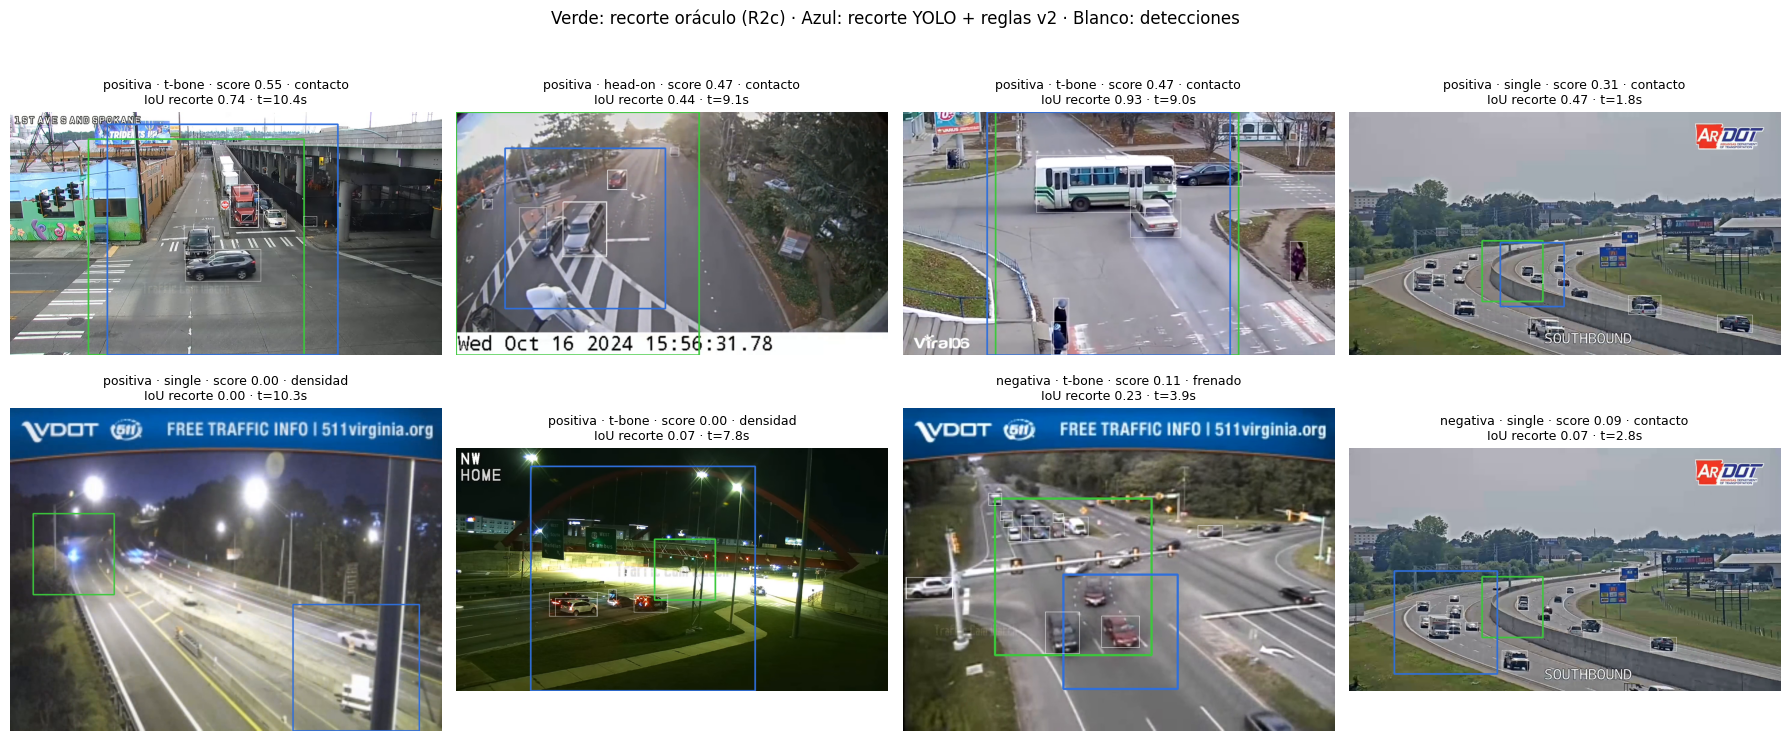

In [ ]:
# ===== 11. Figura: recorte oráculo (verde) vs YOLO (azul) =====
muestra = pd.concat([pos.sort_values('score', ascending=False).head(4), pos.sort_values('score').head(2),
                     neg.sort_values('score', ascending=False).head(2)]).drop_duplicates('key')
fig, axs = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, r in zip(axs.flat, muestra.itertuples()):
    t = r.t_evento if np.isfinite(r.t_evento) else (r.t_choque if r.y else (r.inicio + r.fin) / 2)
    cap = cv2.VideoCapture(r.ruta_local); cap.set(cv2.CAP_PROP_POS_MSEC, 1000 * t); ok, f = cap.read(); cap.release()
    if not ok: continue
    H, W = f.shape[:2]
    for caja, col in [(cuadro(r.roi, W, H), (60, 200, 60)), (cuadro(r.roi_yolo, W, H), (219, 111, 47))]:
        cv2.rectangle(f, tuple(map(int, caja[:2])), tuple(map(int, caja[2:])), col, 4)
    g = tr_de(r.key)
    for b in g[(g.t - t).abs() < 0.06].itertuples():
        cv2.rectangle(f, (int(b.x1 * W), int(b.y1 * H)), (int(b.x2 * W), int(b.y2 * H)), (255, 255, 255), 1)
    ax.imshow(f[..., ::-1]); ax.axis('off')
    ax.set_title(f'{r.clase} · {r.tipo_real} · score {r.score:.2f} · {r.fuente}\nIoU recorte {r.iou_recorte:.2f} · t={t:.1f}s', fontsize=9)
for ax in axs.flat[len(muestra):]: ax.axis('off')
fig.suptitle('Verde: recorte oráculo (R2c) · Azul: recorte YOLO + reglas v2 · Blanco: detecciones', y=1.0)
fig.tight_layout(); fig.savefig(f'{SALIDA}/rois_yolo_vs_oraculo_{VERSION}.png', dpi=130, bbox_inches='tight'); plt.show()

In [ ]:
# ===== 12. Guardar para R3b =====
out = d[['video', 'clase', 'inicio', 'fin', 'wid', 'roi', 'roi_yolo', 'score', 'alerta', 'fuente', 't_evento',
         'n_tracks', 'iou_recorte', 'choque_dentro']].copy()
for c in ('roi', 'roi_yolo'):
    out[c] = out[c].map(lambda t: str(tuple(float(x) for x in t)))
out.to_csv(f'{SALIDA}/rois_yolo_{HUELLA}.csv', index=False)
fila = comp.iloc[-1]
resumen = dict(huella=HUELLA, version=VERSION, yolo=YOLO_PESOS, imgsz=IMGSZ, conf=CONF, fps=FPS_TRACK, formato_roi='cxcywh',
               reglas=R_V2, auc_val=round(float(mejor.auc_val), 3), auc_test=float(fila['AUC test']),
               alertas_pos=fila['alertas en positivas'], alertas_neg=fila['falsas alarmas'],
               choque_dentro=f'{pos.choque_dentro.sum()}/{len(pos)}', iou_recorte_mediana=round(float(pos.iou_recorte.median()), 3),
               bench=bench[bench.imgsz == IMGSZ].to_dict('records'), bench_todo=bench.to_dict('records'))
if t_frames is not None:
    resumen['ms_por_frame_con_tracking'] = round(1000 * float(np.mean(t_frames)), 2)
json.dump(resumen, open(f'{SALIDA}/resumen_r3a.json', 'w'), indent=1, ensure_ascii=False, default=float)
print('Guardado:', sorted(os.listdir(SALIDA)))
print(json.dumps({k: v for k, v in resumen.items() if k not in ('bench', 'bench_todo', 'reglas')}, indent=1, ensure_ascii=False))
print('\n=== Frases para el reporte ===')
print(f"• Reglas v1 (umbrales a priori): AUC test 0.563. v2 (ajustadas en validación, AUC val {mejor.auc_val:.3f}): "
      f"AUC test {fila['AUC test']:.3f}; alertas {fila['alertas en positivas']} en positivas y {fila['falsas alarmas']} en negativas.")
print(f"• La ROI de YOLO contiene el choque en {pos.choque_dentro.sum()}/{len(pos)} positivas (IoU mediana con el recorte oráculo {pos.iou_recorte.median():.2f}).")
b = bench[bench.imgsz == IMGSZ].img_por_s.max()
print(f"• YOLOv8n a {IMGSZ} px en T4: {b:.0f} img/s con lote → {100 * FPS_TRACK / b:.1f} T4 para 100 cámaras a {FPS_TRACK} fps.")

Guardado: ['cascada_ebfa594f.csv', 'comparacion_oraculo_vs_yolo_ebfa594f.csv', 'costo_ebfa594f.csv', 'pruebas_pareadas_r3b_ebfa594f.csv', 'recortes_oraculo_vs_yolo.png', 'reglas_v1_vs_v2_test.csv', 'resumen_r3a.json', 'resumen_r3b.json', 'roc_oraculo_vs_yolo.png', 'rois_yolo_ebfa594f.csv', 'rois_yolo_vs_oraculo.png', 'rois_yolo_vs_oraculo_v2.png', 'test_roi_yolo_base_ebfa594f.csv', 'test_roi_yolo_lora_ebfa594f.csv', 'tracks_yolov8n_10fps.parquet', 'tracks_yolov8n_960px_conf0.1_10fps_v2.parquet']
{
 "huella": "ebfa594f",
 "version": "v2",
 "yolo": "yolov8n.pt",
 "imgsz": 960,
 "conf": 0.1,
 "fps": 10,
 "formato_roi": "cxcywh",
 "auc_val": 0.72,
 "auc_test": 0.636,
 "alertas_pos": "7/30",
 "alertas_neg": "2/30",
 "choque_dentro": "20/30",
 "iou_recorte_mediana": 0.136
}

=== Frases para el reporte ===
• Reglas v1 (umbrales a priori): AUC test 0.563. v2 (ajustadas en validación, AUC val 0.720): AUC test 0.636; alertas 7/30 en positivas y 2/30 en negativas.
• La ROI de YOLO contiene el cho